**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 6**
Ingeniería de características (FE)

---

*   NOMBRE: -----------Brayan Ortega Armendáriz. Equipo 35-------------------------
*   MATRÍCULA: ----A01561888----------------------------

En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Instalar las bibliotecas necesarias
!pip install category_encoders

In [1]:
%pip install category-encoders

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from scipy.stats import probplot
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders.binary import BinaryEncoder

1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [3]:
    # Cargar todos los registros del archivo
compu_df = pd.read_csv("computer_prices_all.csv")

# Guardar la dimensionalidad para comprobar la carga
dimensionalidadInicial = compu_df.shape

print(f"Dimensionalidad inicial: {dimensionalidadInicial}")

# Mostrar solamente una muestra de los datos
compu_df.head()

# Mostrar el resumen de tipos y valores no nulos
compu_df.info()

# Seleccionar las columnas con datos numéricos
columnasNumericas = compu_df.select_dtypes(
    include="number"
).columns.tolist()

# Seleccionar las columnas que no son numéricas
columnasTexto = compu_df.select_dtypes(
    exclude="number"
).columns.tolist()

# Guardar las cantidades encontradas
cantidadColumnasNumericas = len(columnasNumericas)
cantidadColumnasTexto = len(columnasTexto)

print(f"\nColumnas numéricas: {cantidadColumnasNumericas}")
print(f"Columnas de texto: {cantidadColumnasTexto}")

print("\nNombres de las columnas numéricas:")
print(columnasNumericas)

print("\nNombres de las columnas de texto:")
print(columnasTexto)

# Contar los valores diferentes de cada columna
valoresUnicos = compu_df.nunique()

print("Cantidad de valores únicos por columna:")
print(valoresUnicos.to_string())

# Definir las columnas solicitadas para su eliminación
columnasEliminar = [
    "model",
    "cpu_model"
]

# Eliminar las columnas y guardar el resultado en el mismo dataframe
compu_df = compu_df.drop(
    columns=columnasEliminar
)

# Comprobar la nueva dimensionalidad
dimensionalidadFinal = compu_df.shape

print(f"Dimensionalidad después de eliminar las columnas: {dimensionalidadFinal}")
print("\nColumnas restantes:")
print(compu_df.columns.tolist())

Dimensionalidad inicial: (100000, 33)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 33 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  str    
 1   brand                100000 non-null  str    
 2   model                100000 non-null  str    
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  str    
 5   form_factor          100000 non-null  str    
 6   cpu_brand            100000 non-null  str    
 7   cpu_model            100000 non-null  str    
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  cpu_base_ghz         100000 non-null  float64
 12  cpu_boost_ghz        100000 non-null  float64
 13  gpu_brand            100000 non-null  str    
 14  gpu_model            100000 non-null  str 

Aqui en un principio teniamos 100,000 registros, llevé a cabo un análisis de valores únicos, a partir de este obtive lo siguiente... model,  presenta 99,036 valores distintos y `cpu_model` 26,971, por lo que ambas variables tienen una cardinalidad elevada, comento que se eliminaron `model` y `cpu_model`. La primera generaría una cantidad excesiva de categorías durante la codificación, mientras que la información general de `cpu_model` ya está representada parcialmente.

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.
* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

Cantidad de registros duplicados: 0

Cantidad total de valores faltantes: 0

Valores faltantes por columna:


,cantidad_faltantes
device_type,0
brand,0
release_year,0
os,0
form_factor,0
cpu_brand,0
cpu_tier,0
cpu_cores,0
cpu_threads,0
cpu_base_ghz,0



Estadísticas descriptivas de las variables numéricas:


,count,mean,std,min,25%,50%,75%,max
release_year,100000.0,2022.320850,2.025761,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.153490,1.373175,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.515740,5.044092,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.372700,9.718426,4.00,12.00,16.00,24.00,56.00
cpu_base_ghz,100000.0,2.591322,0.336435,2.00,2.40,2.60,2.80,3.40
cpu_boost_ghz,100000.0,3.531310,0.350024,2.80,3.30,3.50,3.80,4.50
gpu_tier,100000.0,2.991350,1.459643,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.152180,3.964926,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.706400,31.902684,8.00,16.00,32.00,64.00,144.00
storage_gb,100000.0,903.936000,774.243654,256.00,512.00,512.00,1024.00,4096.00



Estadísticas descriptivas de las variables categóricas:


...

,frecuencia
display_type,
LED,32000
OLED,21910
IPS,17742
Mini-LED,12188
QLED,10069
VA,6091



Variable: resolution


,frecuencia
resolution,
1920x1080,47993
2560x1600,14887
2560x1440,14509
3840x2160,10950
2880x1800,5954
3440x1440,5707



Variable: wifi


,frecuencia
wifi,
Wi-Fi 6,46149
Wi-Fi 6E,25923
Wi-Fi 5,19926
Wi-Fi 7,8002


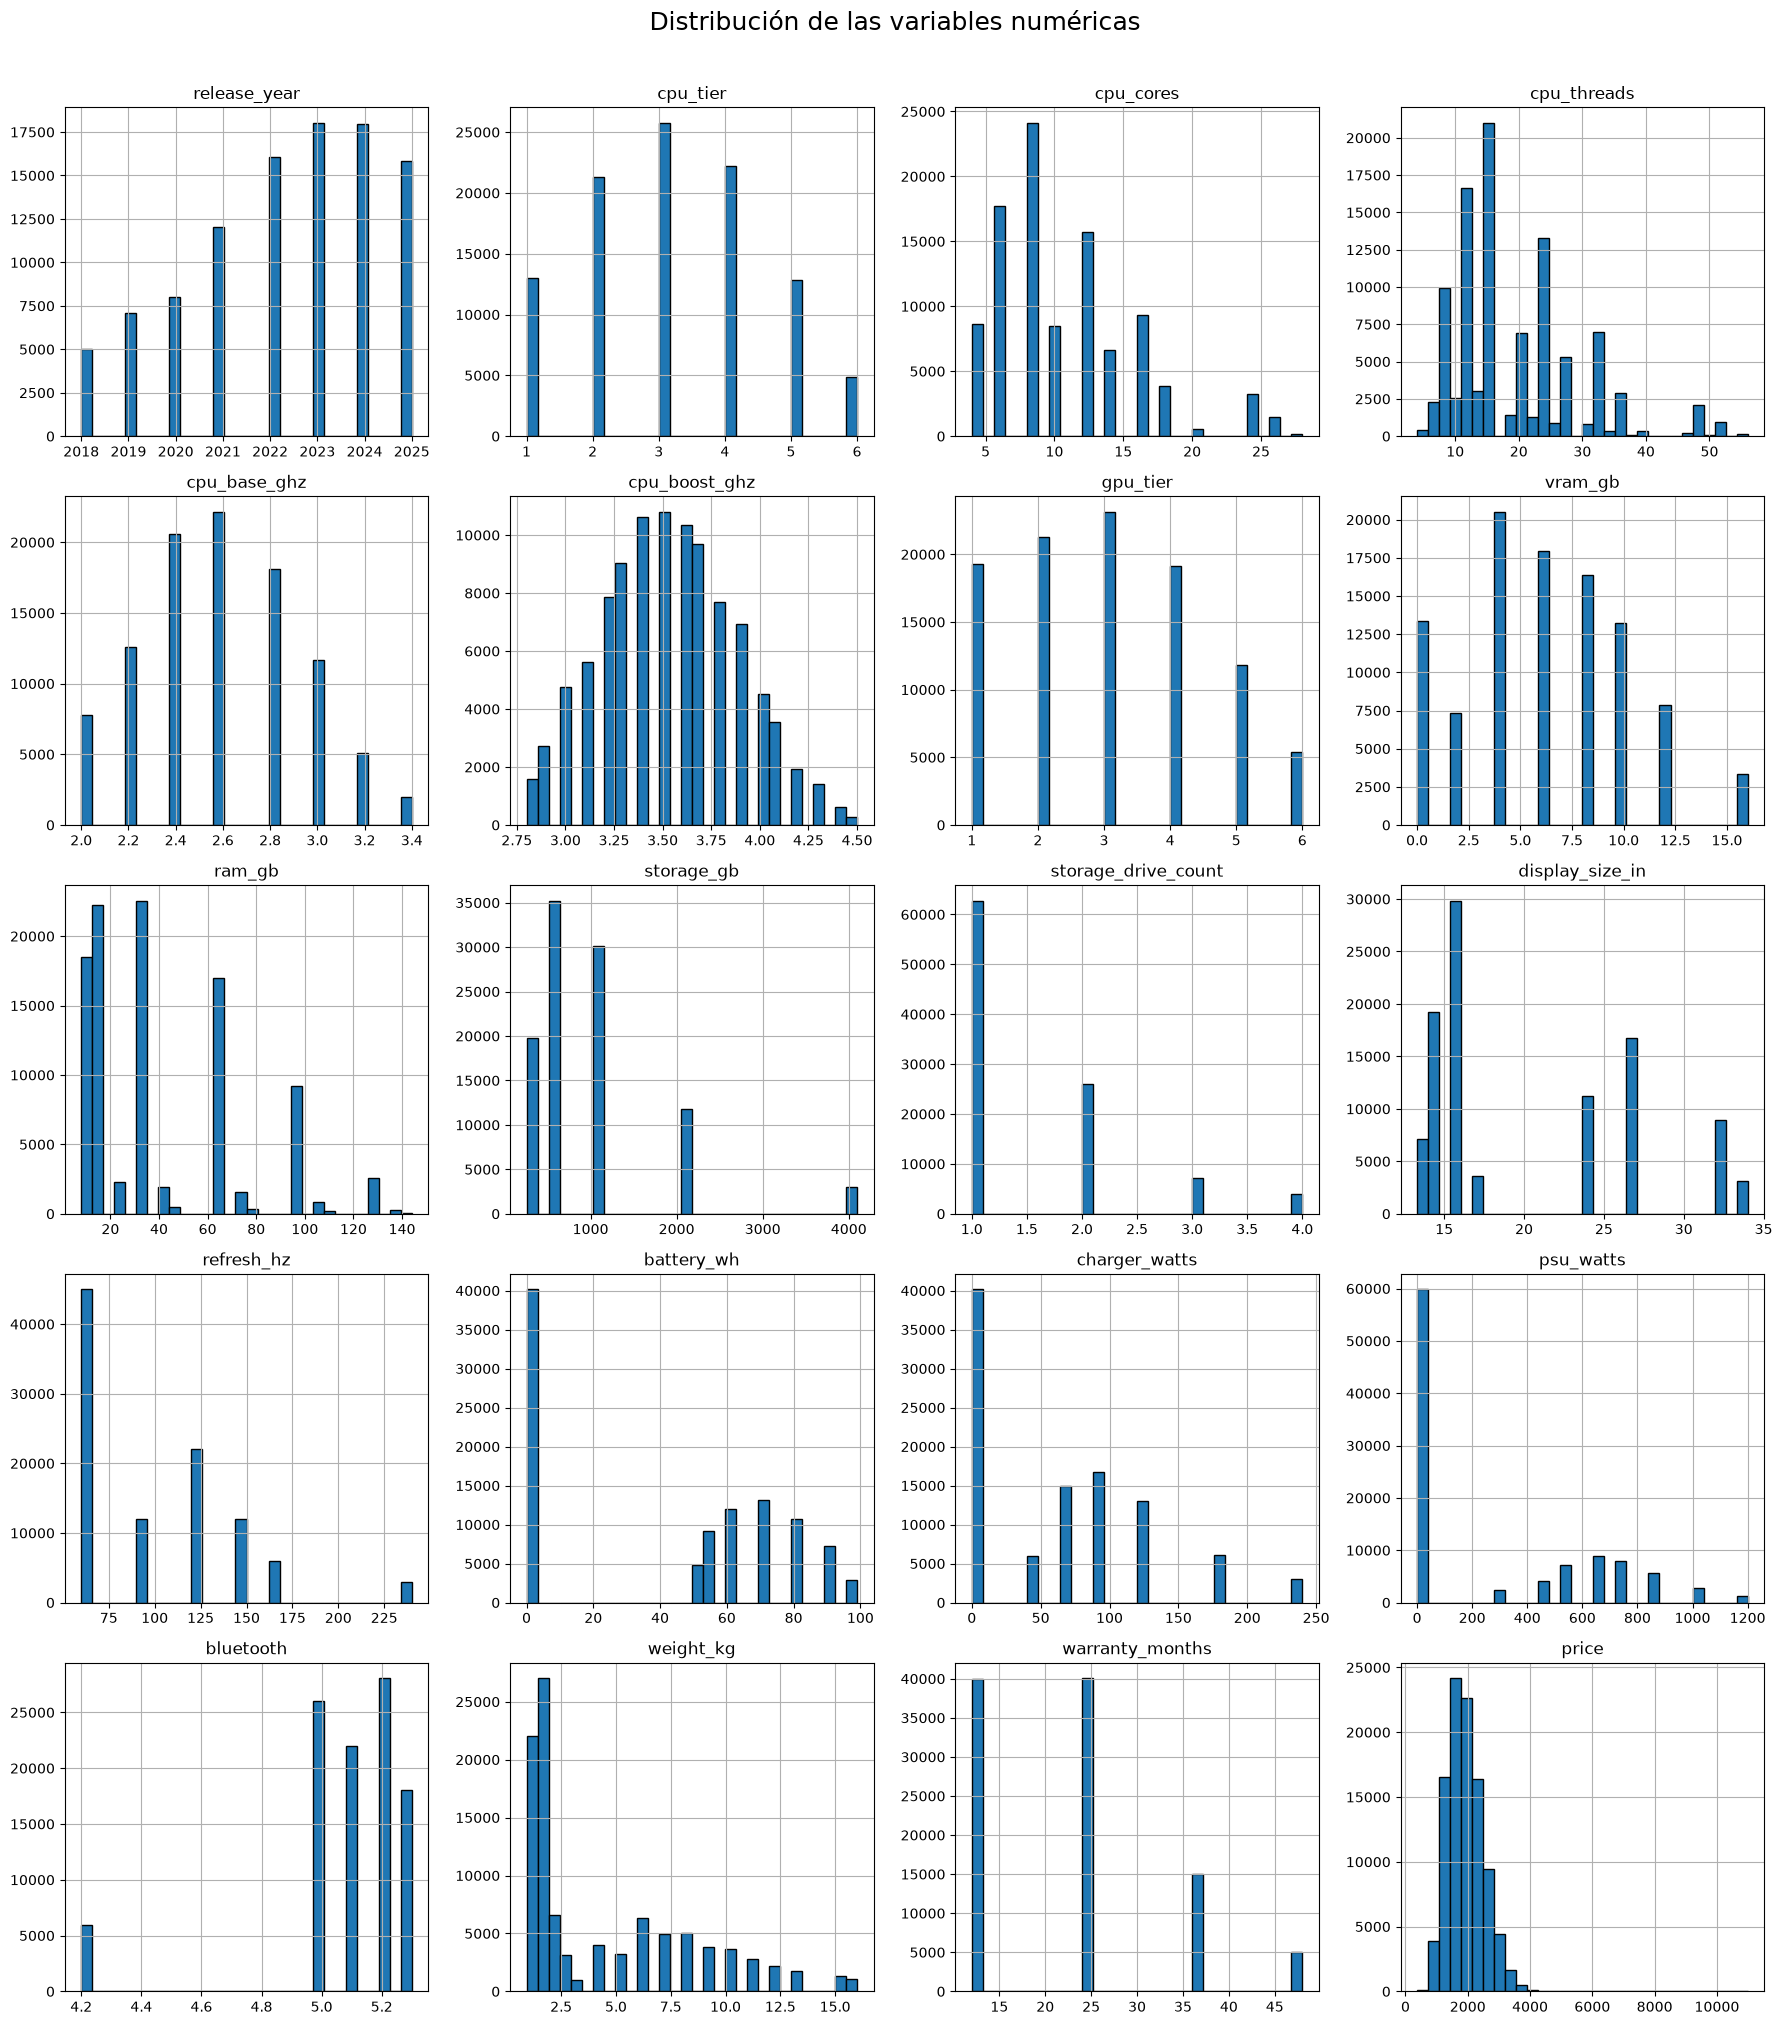

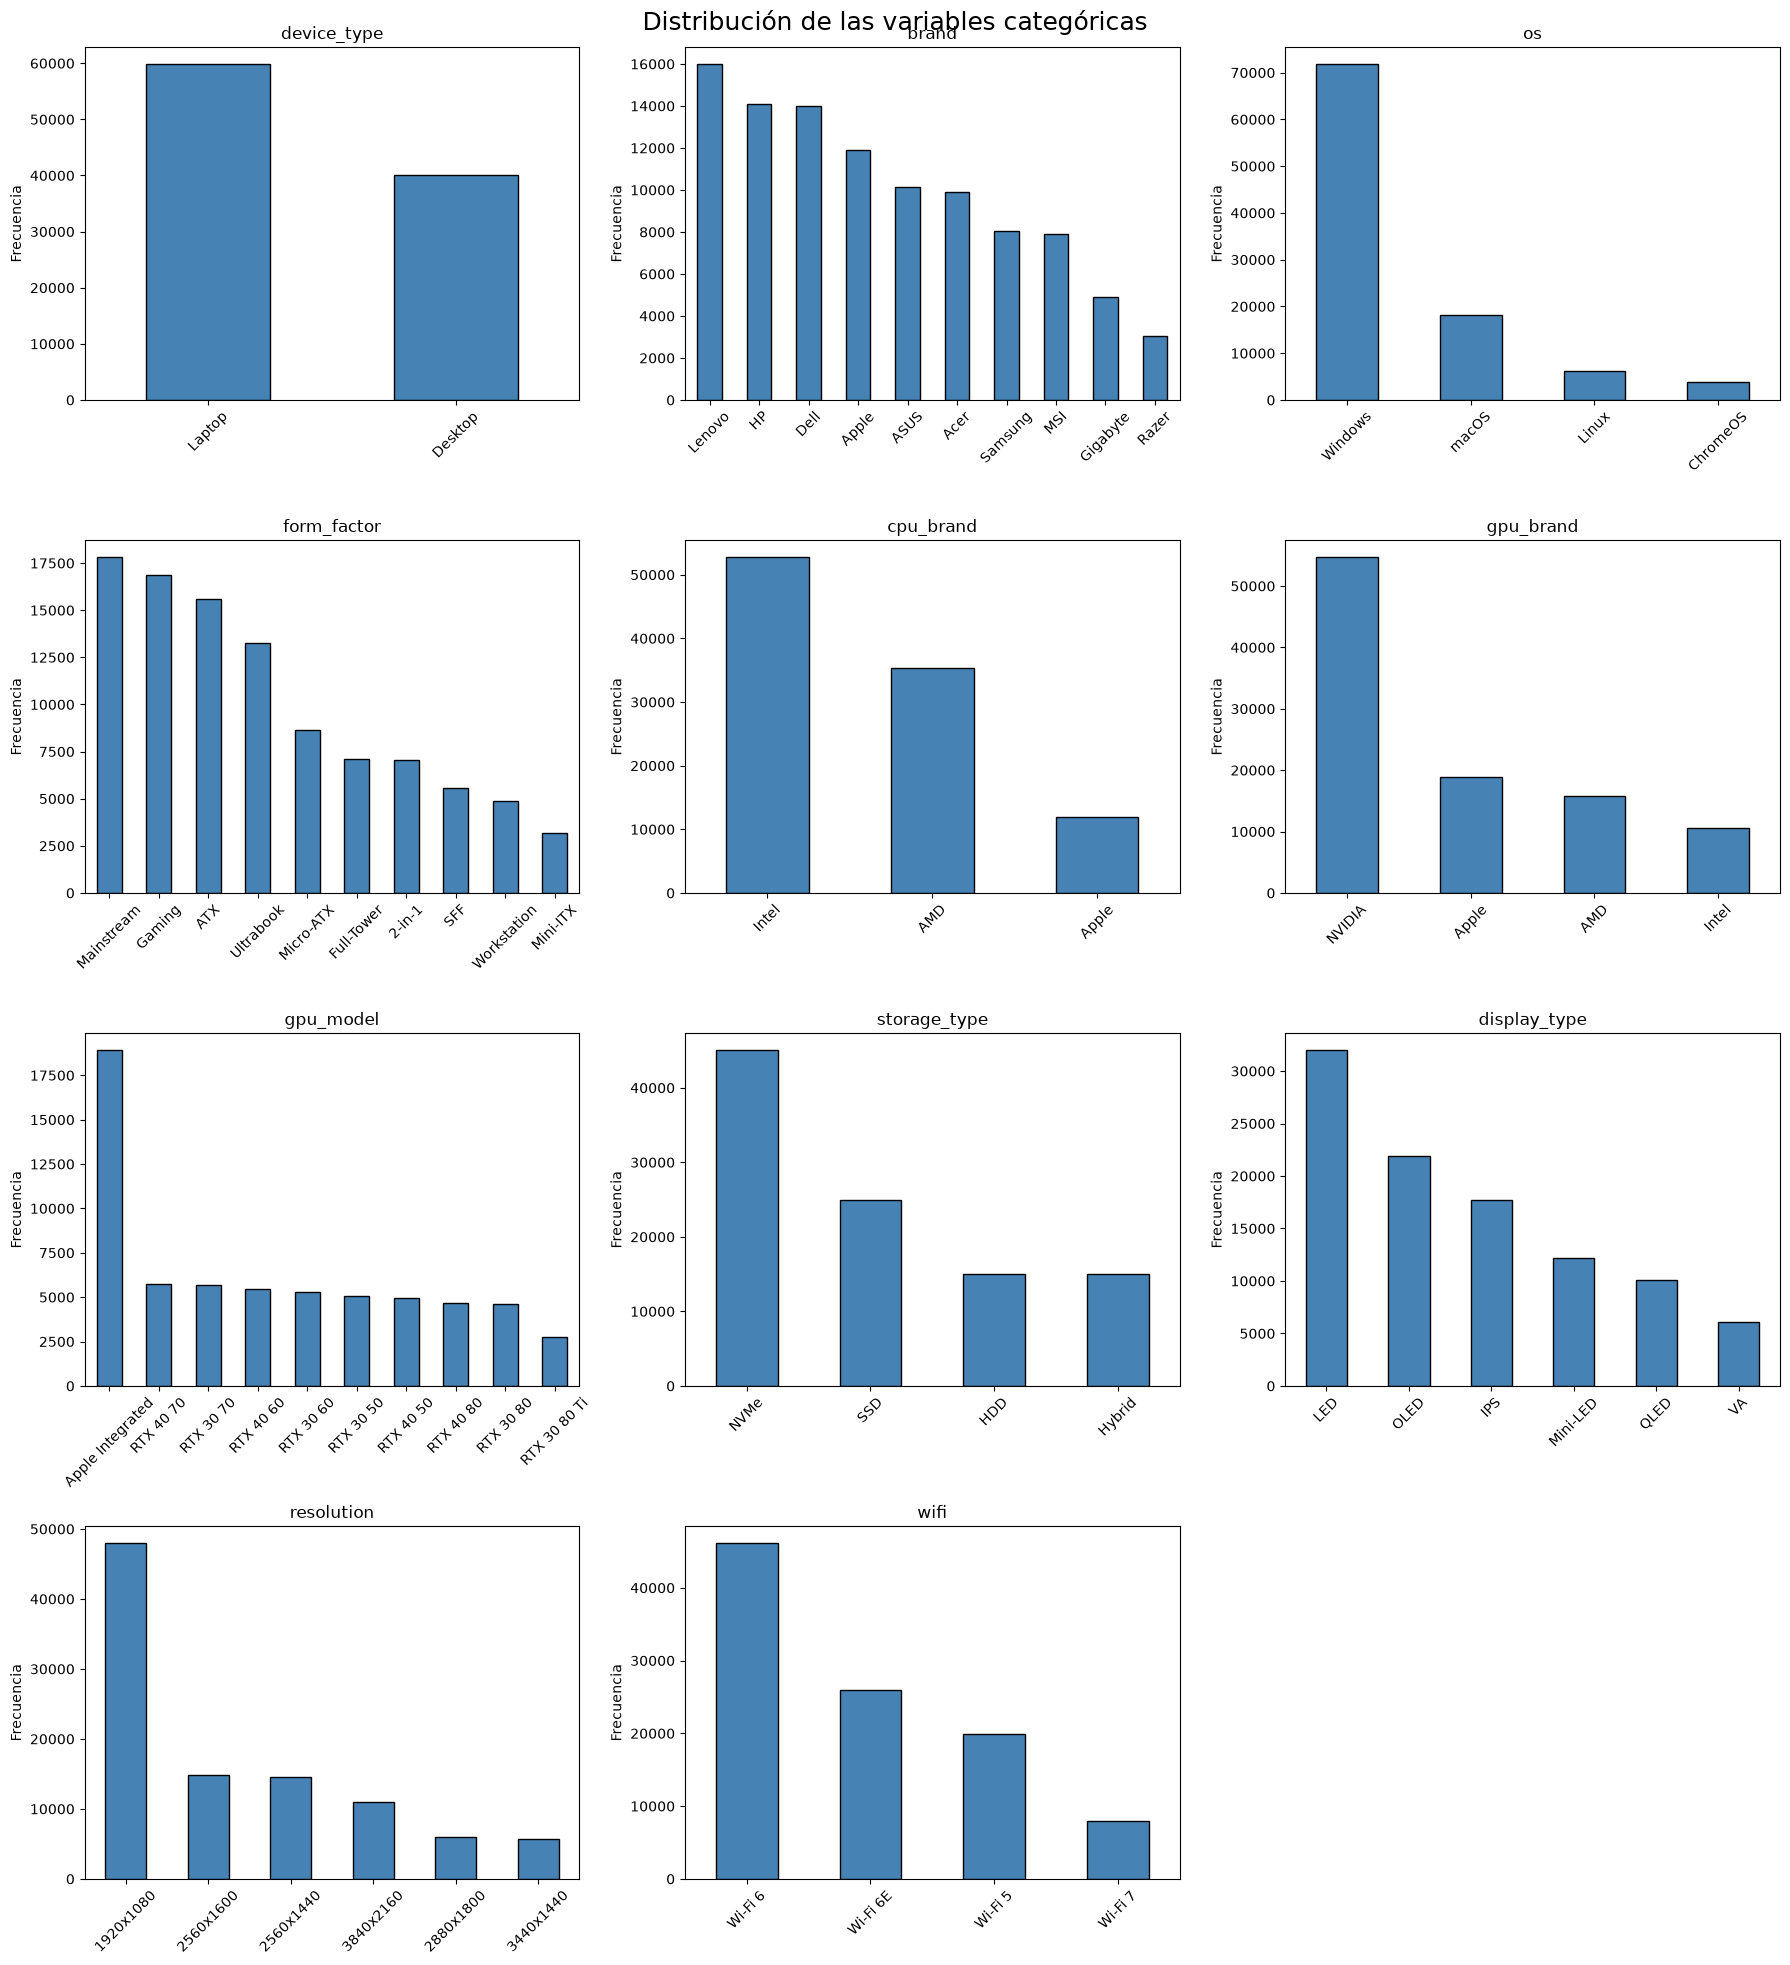

In [4]:
# ------------------------------------------------------------
# PROBLEMA 2
# Verificar duplicados y faltantes, obtener estadísticas
# descriptivas y visualizar cada variable individualmente.
# ------------------------------------------------------------

# 1. Verificar registros duplicados
cantidadDuplicados = compu_df.duplicated().sum()

print(f"Cantidad de registros duplicados: {cantidadDuplicados}")


# 2. Verificar valores faltantes
valoresFaltantes = compu_df.isna().sum()
cantidadTotalFaltantes = valoresFaltantes.sum()

print(f"\nCantidad total de valores faltantes: {cantidadTotalFaltantes}")
print("\nValores faltantes por columna:")
display(
    valoresFaltantes.to_frame(
        name="cantidad_faltantes"
    )
)


# 3. Separar las columnas numéricas y categóricas
columnasNumericas = compu_df.select_dtypes(
    include="number"
).columns.tolist()

columnasCategoricas = compu_df.select_dtypes(
    exclude="number"
).columns.tolist()


# 4. Obtener estadísticas descriptivas de las numéricas
estadisticasNumericas = (
    compu_df[columnasNumericas]
    .describe()
    .T
)

print("\nEstadísticas descriptivas de las variables numéricas:")
display(estadisticasNumericas)


# 5. Obtener estadísticas descriptivas de las categóricas
estadisticasCategoricas = (
    compu_df[columnasCategoricas]
    .describe()
    .T
)

print("\nEstadísticas descriptivas de las variables categóricas:")
display(estadisticasCategoricas)


# 6. Mostrar las tablas de frecuencia de las categóricas
print("\nTablas de frecuencia de las variables categóricas:")

for columna in columnasCategoricas:
    tablaFrecuencia = (
        compu_df[columna]
        .value_counts(dropna=False)
        .to_frame(name="frecuencia")
    )

    print(f"\nVariable: {columna}")
    display(tablaFrecuencia)


# 7. Generar histogramas de las variables numéricas
compu_df[columnasNumericas].hist(
    bins=30,
    figsize=(18, 20),
    layout=(5, 4),
    edgecolor="black"
)

plt.suptitle(
    "Distribución de las variables numéricas",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()


# 8. Generar diagramas de barras de las categóricas
# Para variables con más de 10 categorías se muestran
# solamente las 10 categorías más frecuentes.

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(18, 20)
)

axes = axes.flatten()

for posicion, columna in enumerate(columnasCategoricas):
    frecuenciasGrafica = (
        compu_df[columna]
        .value_counts()
        .head(10)
    )

    frecuenciasGrafica.plot(
        kind="bar",
        ax=axes[posicion],
        color="steelblue",
        edgecolor="black"
    )

    axes[posicion].set_title(columna)
    axes[posicion].set_xlabel("")
    axes[posicion].set_ylabel("Frecuencia")
    axes[posicion].tick_params(
        axis="x",
        rotation=45
    )

# Ocultar los espacios que no contienen una gráfica
for posicionVacia in range(
    len(columnasCategoricas),
    len(axes)
):
    axes[posicionVacia].set_visible(False)

fig.suptitle(
    "Distribución de las variables categóricas",
    fontsize=18
)

plt.tight_layout()
plt.show()

Bueno, pues en este caso el dataframe no contenía registros duplicados ni valores faltantes, por lo que no fue necesario eliminar o agregar observaciones, despues de retirar las variables de model y 
cpu_model, conservamos once variables numéricas y once categóricas, el análisis muestra que los dispositivos fueron lanzados entre '2018' y '2025', y tienen un precio medio aproximado de '1,928.76'.

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.
* Incluye una breve justificación de tus decisiones.

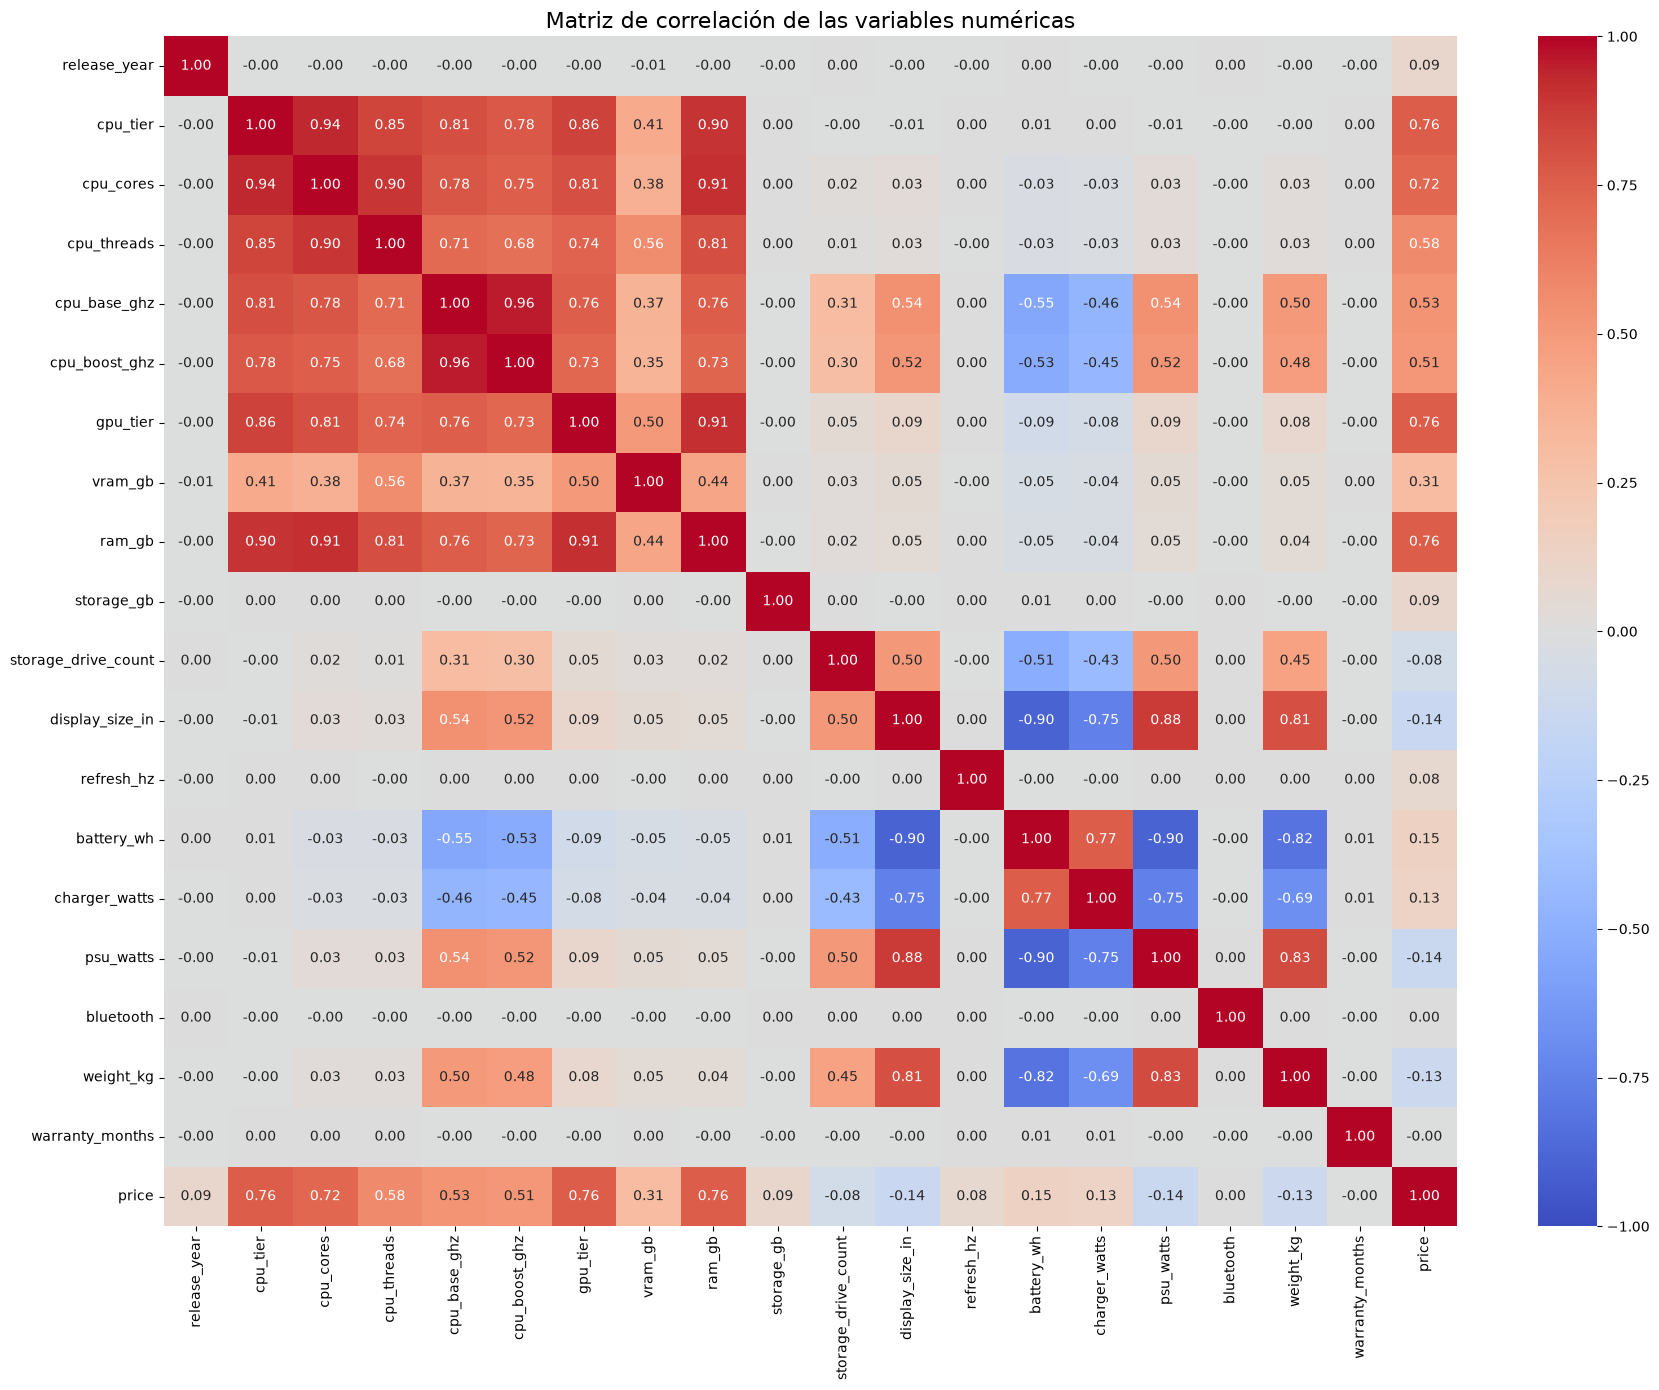

Pares de variables con correlación superior a 0.9:


,variable_1,variable_2,correlacion
0,cpu_base_ghz,cpu_boost_ghz,0.960884
1,cpu_tier,cpu_cores,0.937376
2,gpu_tier,ram_gb,0.912918
3,cpu_cores,ram_gb,0.906770



Columnas eliminadas por redundancia: ['cpu_boost_ghz', 'cpu_cores', 'ram_gb']
Dimensionalidad después de eliminar redundancias: (100000, 28)

Columnas restantes:
['device_type', 'brand', 'release_year', 'os', 'form_factor', 'cpu_brand', 'cpu_tier', 'cpu_threads', 'cpu_base_ghz', 'gpu_brand', 'gpu_model', 'gpu_tier', 'vram_gb', 'storage_type', 'storage_gb', 'storage_drive_count', 'display_type', 'display_size_in', 'resolution', 'refresh_hz', 'battery_wh', 'charger_watts', 'psu_watts', 'wifi', 'bluetooth', 'weight_kg', 'warranty_months', 'price']


In [5]:

# PROBLEMA 3


# 1. Seleccionar únicamente las variables numéricas
datosNumericos = compu_df.select_dtypes(
    include="number"
)

# Calcular la matriz de correlación
matrizCorrelacion = datosNumericos.corr()


# 2. Dibujar el mapa de calor
plt.figure(figsize=(18, 14))

sns.heatmap(
    matrizCorrelacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Matriz de correlación de las variables numéricas",
    fontsize=16
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# 3. Se procede a extraer solamente la parte superior de la matriz
# para evitar imprimir cada relación dos veces
trianguloSuperior = np.triu(
    np.ones_like(
        matrizCorrelacion,
        dtype=bool
    ),
    k=1
)

paresCorrelacion = (
    matrizCorrelacion
    .where(trianguloSuperior)
    .stack()
    .reset_index()
)

paresCorrelacion.columns = [
    "variable_1",
    "variable_2",
    "correlacion"
]


# 4. Aqui hay que filtrar los pares con correlación superior a 0.9
correlacionesAltas = (
    paresCorrelacion[
        paresCorrelacion["correlacion"] > 0.9
    ]
    .sort_values(
        by="correlacion",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Pares de variables con correlación superior a 0.9:")
display(correlacionesAltas)


# 5. Luego Eliminar las variables consideradas redundantes
# Se conserva cpu_base_ghz porque representa la frecuencia
# sostenida del procesador y se elimina la frecuencia máxima.
#
# Se conservan cpu_tier y gpu_tier porque resumen de manera
# general el nivel de desempeño del procesador y de la GPU.

columnasRedundantes = [
    "cpu_boost_ghz",
    "cpu_cores",
    "ram_gb"
]

compu_df = compu_df.drop(
    columns=columnasRedundantes
)


# 6. Ahora Comprobar el resultado de la eliminación
dimensionalidadDespuesCorrelacion = compu_df.shape

print(
    "\nColumnas eliminadas por redundancia:",
    columnasRedundantes
)

print(
    "Dimensionalidad después de eliminar redundancias:",
    dimensionalidadDespuesCorrelacion
)

print("\nColumnas restantes:")
print(compu_df.columns.tolist())

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.
* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.
* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.
* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.

Año utilizado para el cálculo: 2026

Valores que delimitan los bins de vram_gb:
[ 0.  4.  6.  8. 16.]

Cantidad de computadoras en cada bin:
vram_gb
0    20757
1    20517
2    17930
3    40796
Name: count, dtype: int64


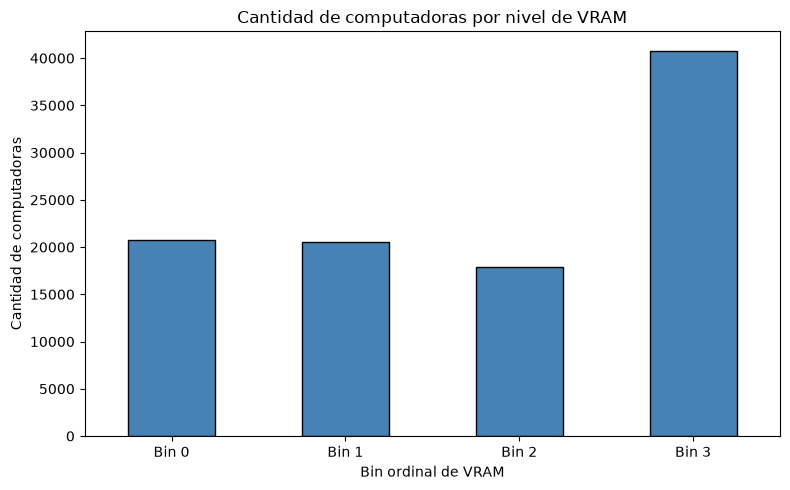

In [6]:
# PROBLEMA 4: Ingeniería de características

# 1. Crear una copia independiente del dataframe depurado
compu_transf = compu_df.copy()


# 2. Calcular los años transcurridos desde el lanzamiento

# Obtener automáticamente el año actual
anioActual = date.today().year

# Restar el año de lanzamiento al año actual
compu_transf["years_since_release"] = (
    anioActual - compu_transf["release_year"]
)

# Eliminar la columna original porque su información ya fue transformada
compu_transf = compu_transf.drop(
    columns=["release_year"]
)


# 3. Dividir vram_gb en cuatro intervalos ordinales basados en cuantiles

discretizadorVram = KBinsDiscretizer(
    n_bins=4,
    encode="ordinal",
    strategy="quantile",
    quantile_method="averaged_inverted_cdf"
)

# fit_transform aprende los límites y transforma los valores
compu_transf["vram_gb"] = (
    discretizadorVram
    .fit_transform(compu_transf[["vram_gb"]])
    .ravel()
    .astype("int64")
)


# 4. Mostrar los valores que delimitan los intervalos

limitesVram = discretizadorVram.bin_edges_[0]

print("Año utilizado para el cálculo:", anioActual)
print("\nValores que delimitan los bins de vram_gb:")
print(limitesVram)

print("\nCantidad de computadoras en cada bin:")
print(
    compu_transf["vram_gb"]
    .value_counts()
    .sort_index()
)


# 5. Graficar la cantidad de observaciones en cada bin

frecuenciaBinsVram = (
    compu_transf["vram_gb"]
    .value_counts()
    .sort_index()
)

ax = frecuenciaBinsVram.plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Cantidad de computadoras por nivel de VRAM")
ax.set_xlabel("Bin ordinal de VRAM")
ax.set_ylabel("Cantidad de computadoras")
ax.set_xticklabels(
    ["Bin 0", "Bin 1", "Bin 2", "Bin 3"],
    rotation=0
)

plt.tight_layout()
plt.show()

Para evitarme hacer alteraciones, lo primero que hice fue crear compu_transf como una copia del dataframe depurado para realizar las transformaciones sin alterar el objeto anterior, luego para trabajar utilice la variable release_year se sustituyó por years_since_release, que representa directamente la antigüedad de cada computadora. Con otra variable, vram_gb se discretizó en cuatro niveles ordinales como cuantiles, donde los valores de 0 a 3 representan cantidades progresivamente mayores de memoria de video

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.
* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

Relación entre el tipo de dispositivo y las variables de potencia:
             cantidad_dispositivos  cargador_en_cero  fuente_en_cero  \
device_type                                                            
Desktop                      40156             40156               0   
Laptop                       59844                 0           59844   

             potencia_media_cargador  potencia_media_fuente  
device_type                                                  
Desktop                     0.000000             678.654497  
Laptop                    102.572438               0.000000  

Registros con cargador y fuente simultáneamente: 0
Registros con ambas potencias en cero: 0


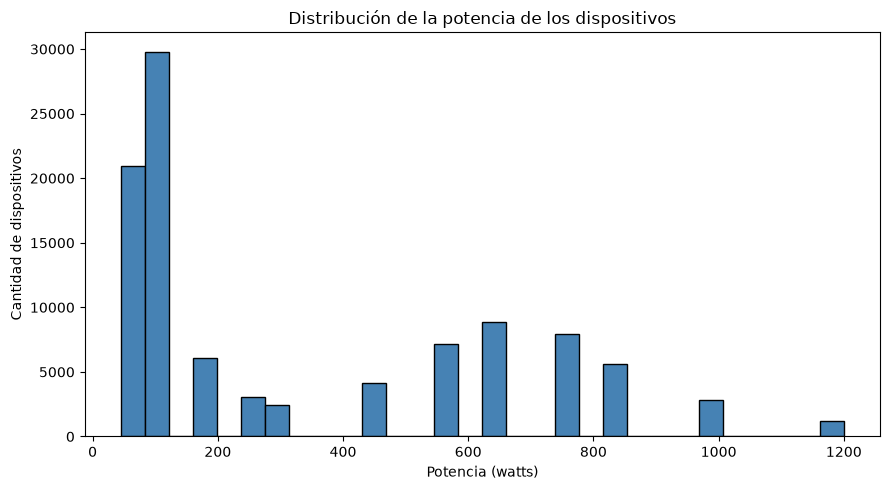

Dimensionalidad después de combinar las variables: (100000, 27)


In [7]:
# PROBLEMA 5: Combinar las variables de potencia

# 1. Analizar los ceros de acuerdo con el tipo de dispositivo

analisisPotencia = compu_transf.groupby(
    "device_type"
).agg(
    cantidad_dispositivos=("device_type", "size"),
    cargador_en_cero=(
        "charger_watts",
        lambda columna: (columna == 0).sum()
    ),
    fuente_en_cero=(
        "psu_watts",
        lambda columna: (columna == 0).sum()
    ),
    potencia_media_cargador=("charger_watts", "mean"),
    potencia_media_fuente=("psu_watts", "mean")
)

print("Relación entre el tipo de dispositivo y las variables de potencia:")
print(analisisPotencia)


# Comprobar que las variables sean mutuamente excluyentes

registrosConAmbasPotencias = (
    (compu_transf["charger_watts"] > 0)
    & (compu_transf["psu_watts"] > 0)
).sum()

registrosSinPotencia = (
    (compu_transf["charger_watts"] == 0)
    & (compu_transf["psu_watts"] == 0)
).sum()

print(
    "\nRegistros con cargador y fuente simultáneamente:",
    registrosConAmbasPotencias
)

print(
    "Registros con ambas potencias en cero:",
    registrosSinPotencia
)


# 2. Crear power_watts con la potencia correspondiente de cada dispositivo

# La suma funciona porque solamente una de las dos columnas contiene
# una potencia mayor que cero en cada registro.
compu_transf["power_watts"] = (
    compu_transf["charger_watts"]
    + compu_transf["psu_watts"]
)


# Crear el histograma de la potencia combinada

ax = compu_transf["power_watts"].plot(
    kind="hist",
    bins=30,
    figsize=(9, 5),
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Distribución de la potencia de los dispositivos")
ax.set_xlabel("Potencia (watts)")
ax.set_ylabel("Cantidad de dispositivos")

plt.tight_layout()
plt.show()


# 3. Eliminar las columnas originales

compu_transf = compu_transf.drop(
    columns=[
        "charger_watts",
        "psu_watts"
    ]
)

print(
    "Dimensionalidad después de combinar las variables:",
    compu_transf.shape
)

Los ceros de charger_watts y psu_watts son valores estructurales y no datos faltantes, el cargador corresponde a las laptops, y por el otro lado la fuente de poder es a las computadoras de escritorio. Como ambas variables son mutuamente excluyentes, se combinaron en power_watts.

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.
* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

Valores mínimos de las variables continuas:
weight_kg        0.92
power_watts     45.00
price          372.99
dtype: float64

Comparación de las transformaciones de price:
transformacion     sesgo  cantidad_outliers
      Original  0.986644                976
     Logaritmo -0.133105                386
 Raíz cuadrada  0.332253                364
       Box-Cox -0.000238                317

Lambda encontrado por Box-Cox para price: 0.15041806876928954


/var/folders/xd/vjhkkn0n6cn33jwldgcbzx140000gn/T/ipykernel_83049/293903534.py:150: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[fila, 1].boxplot(
/var/folders/xd/vjhkkn0n6cn33jwldgcbzx140000gn/T/ipykernel_83049/293903534.py:150: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[fila, 1].boxplot(
/var/folders/xd/vjhkkn0n6cn33jwldgcbzx140000gn/T/ipykernel_83049/293903534.py:150: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[fila, 1].boxplot(
/var/folders/xd/vjhkkn0n6cn33jwldgcbzx140000gn/T/ipykernel_83049/293903534.py:150: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {

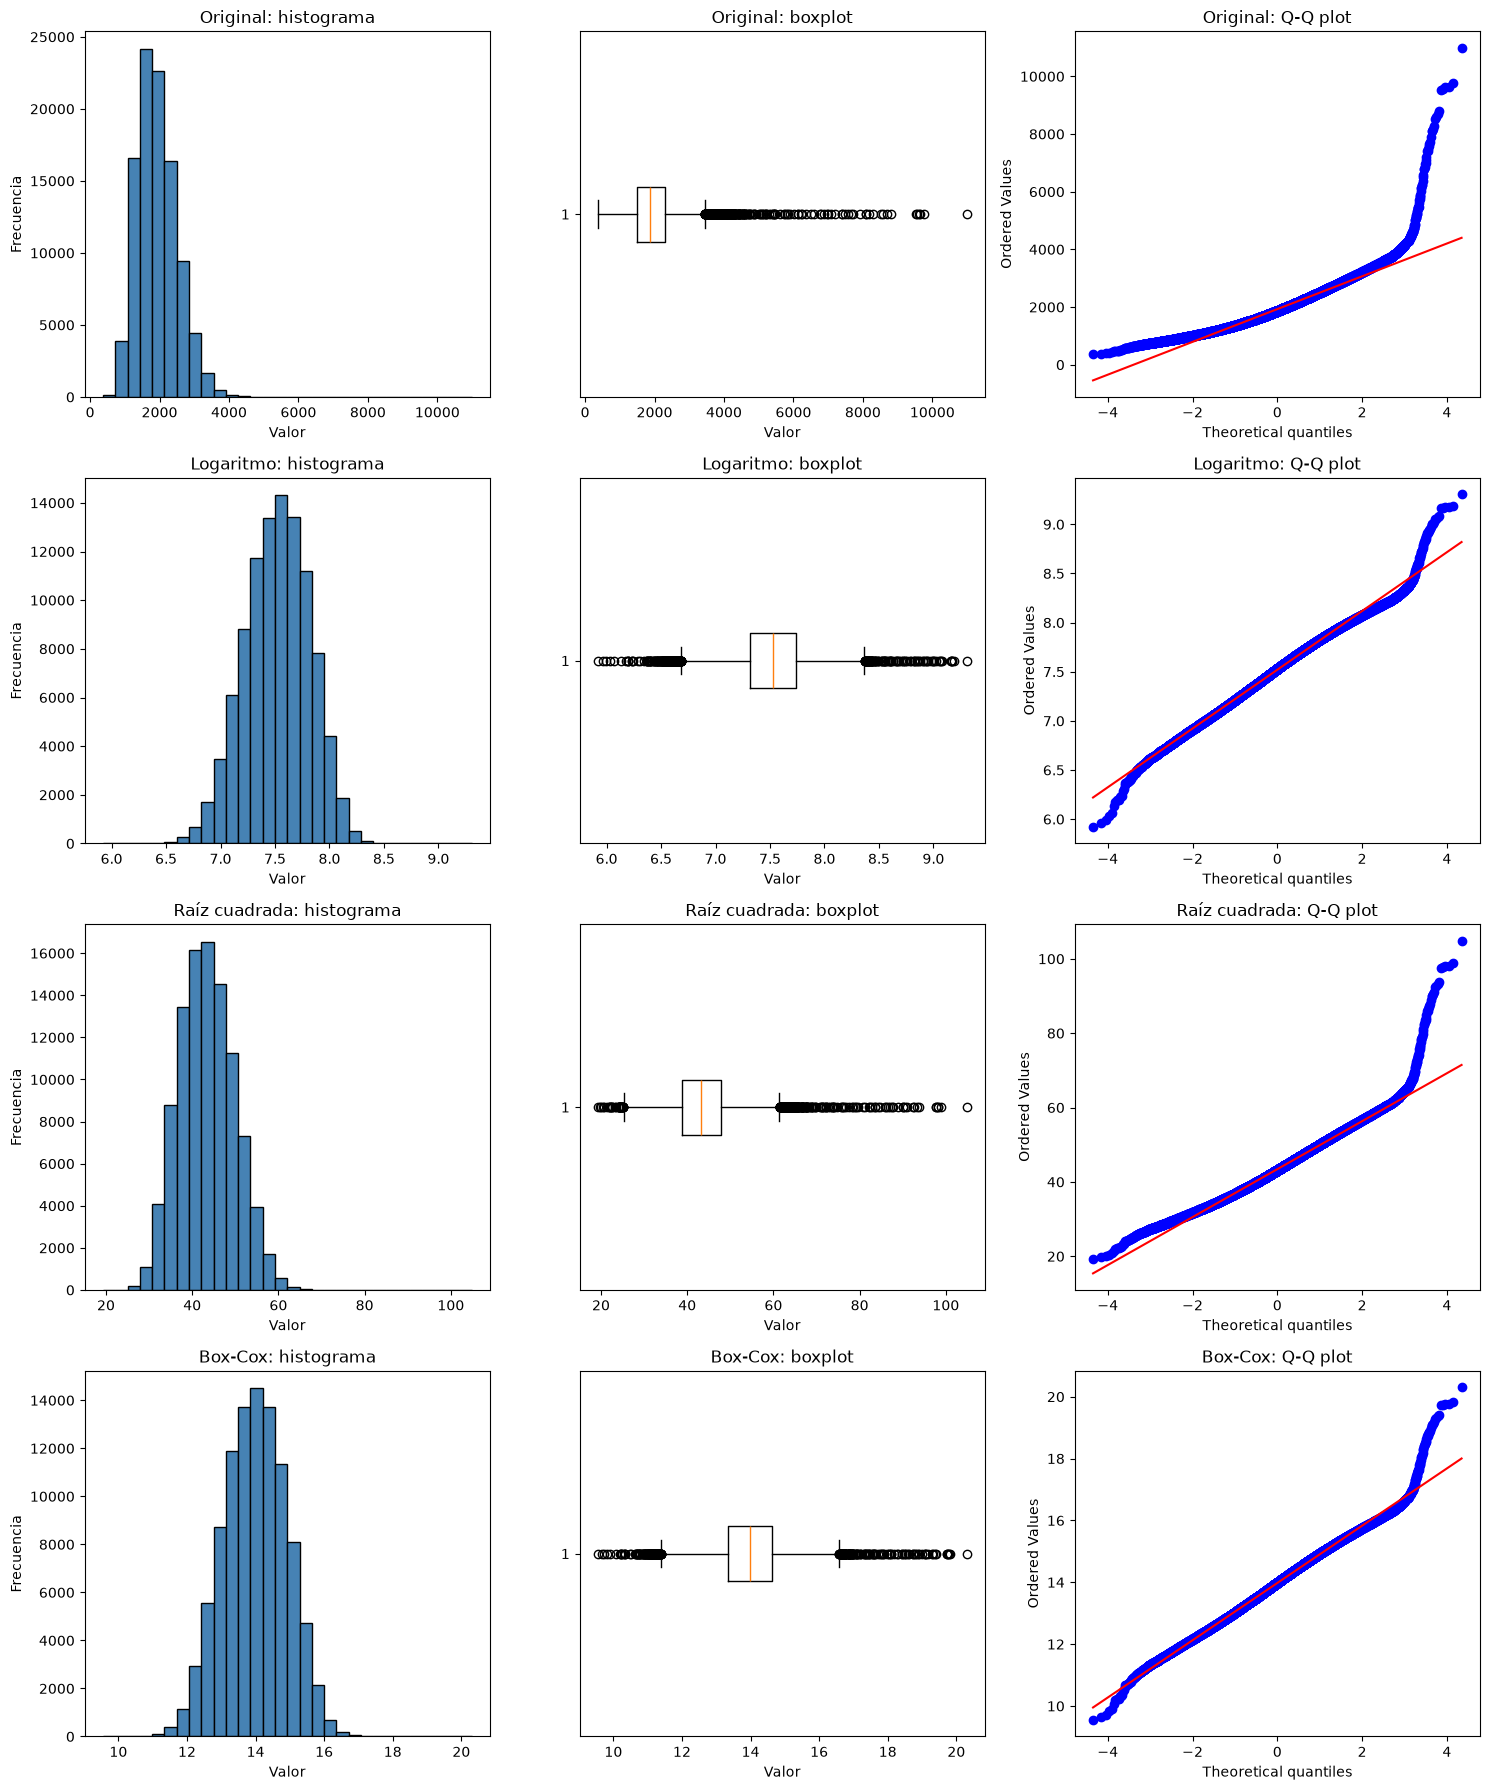


Transformación seleccionada: Box-Cox

Valores lambda utilizados:
weight_kg     -0.480424
power_watts   -0.165033
price          0.150418
Name: lambda, dtype: float64

Dimensionalidad después de las transformaciones: (100000, 27)


In [8]:
# PROBLEMA 6: Transformaciones para disminuir el sesgo

# Estas columnas que se transformarán definitivamente al final del ejercicio
columnasContinuas = [
    "weight_kg",
    "power_watts",
    "price"
]


# 1. Verificar que los valores sean positivos

# Box-Cox y el logaritmo requieren valores mayores que cero.
valoresMinimos = compu_transf[columnasContinuas].min()

print("Valores mínimos de las variables continuas:")
print(valoresMinimos)

if (valoresMinimos <= 0).any():
    raise ValueError(
        "Las transformaciones requieren valores mayores que cero."
    )


# 2. Crear los tres transformadores solicitados

transformadorLogaritmo = FunctionTransformer(
    np.log
)

transformadorRaiz = FunctionTransformer(
    np.sqrt
)

transformadorBoxCox = PowerTransformer(
    method="box-cox",
    standardize=False
)


# 3. Aplicar temporalmente las transformaciones solamente a price

precioOriginal = compu_transf[["price"]].to_numpy()

precioLogaritmo = (
    transformadorLogaritmo
    .fit_transform(precioOriginal)
    .ravel()
)

precioRaiz = (
    transformadorRaiz
    .fit_transform(precioOriginal)
    .ravel()
)

precioBoxCox = (
    transformadorBoxCox
    .fit_transform(precioOriginal)
    .ravel()
)

lambdaPrecio = transformadorBoxCox.lambdas_[0]


# 4. Función para contar valores atípicos mediante IQR

def contarAtipicosIQR(datos):
    serie = pd.Series(datos)

    primerCuartil = serie.quantile(0.25)
    tercerCuartil = serie.quantile(0.75)

    rangoIntercuartil = tercerCuartil - primerCuartil

    limiteInferior = primerCuartil - 1.5 * rangoIntercuartil
    limiteSuperior = tercerCuartil + 1.5 * rangoIntercuartil

    cantidadAtipicos = (
        (serie < limiteInferior)
        | (serie > limiteSuperior)
    ).sum()

    return cantidadAtipicos


# 5. Reunir la variable original y las tres transformaciones

transformacionesPrecio = {
    "Original": precioOriginal.ravel(),
    "Logaritmo": precioLogaritmo,
    "Raíz cuadrada": precioRaiz,
    "Box-Cox": precioBoxCox
}


# 6. Calcular sesgo y cantidad de valores atípicos

resultadosTransformaciones = []

for nombreTransformacion, datos in transformacionesPrecio.items():

    resultadosTransformaciones.append({
        "transformacion": nombreTransformacion,
        "sesgo": pd.Series(datos).skew(),
        "cantidad_outliers": contarAtipicosIQR(datos)
    })

comparacionTransformaciones = pd.DataFrame(
    resultadosTransformaciones
)

print("\nComparación de las transformaciones de price:")
print(comparacionTransformaciones.to_string(index=False))

print(
    "\nLambda encontrado por Box-Cox para price:",
    lambdaPrecio
)


# 7. Mostrar histograma, boxplot y Q-Q plot de cada transformación

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(15, 18)
)

for fila, (nombreTransformacion, datos) in enumerate(
    transformacionesPrecio.items()
):

    # Histograma
    axes[fila, 0].hist(
        datos,
        bins=30,
        color="steelblue",
        edgecolor="black"
    )

    axes[fila, 0].set_title(
        f"{nombreTransformacion}: histograma"
    )

    axes[fila, 0].set_xlabel("Valor")
    axes[fila, 0].set_ylabel("Frecuencia")

    # Boxplot
    axes[fila, 1].boxplot(
        datos,
        vert=False
    )

    axes[fila, 1].set_title(
        f"{nombreTransformacion}: boxplot"
    )

    axes[fila, 1].set_xlabel("Valor")

    # Q-Q plot
    probplot(
        datos,
        dist="norm",
        plot=axes[fila, 2]
    )

    axes[fila, 2].set_title(
        f"{nombreTransformacion}: Q-Q plot"
    )

plt.tight_layout()
plt.show()


# 8. Aplicar definitivamente Box-Cox a las variables continuas

lambdasAplicadas = {}

for columna in columnasContinuas:

    transformadorColumna = PowerTransformer(
        method="box-cox",
        standardize=False
    )

    compu_transf[columna] = (
        transformadorColumna
        .fit_transform(compu_transf[[columna]])
        .ravel()
    )

    lambdasAplicadas[columna] = (
        transformadorColumna.lambdas_[0]
    )


print("\nTransformación seleccionada: Box-Cox")

print("\nValores lambda utilizados:")
print(pd.Series(lambdasAplicadas, name="lambda"))

print(
    "\nDimensionalidad después de las transformaciones:",
    compu_transf.shape
)

La distribución original de price presentaba asimetría positiva, indicando una concentración de precios bajos y medios acompañada de una cola hacia los precios altos.

7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [10]:
# PROBLEMA 7: Escalar todas las variables numéricas entre 0 y 1

# 1. Identificar automáticamente las columnas numéricas

columnasNumericas = (
    compu_transf
    .select_dtypes(include="number")
    .columns
    .tolist()
)

print("Cantidad de variables numéricas:", len(columnasNumericas))

print("\nVariables numéricas que serán escaladas:")
print(columnasNumericas)


# 2. Crear el escalador Min-Max

escaladorNumerico = MinMaxScaler(
    feature_range=(0, 1)
)


# 3. Ajustar y transformar las columnas numéricas

# fit_transform calcula el mínimo y máximo de cada columna
# y devuelve sus valores escalados.
compu_transf[columnasNumericas] = (
    escaladorNumerico
    .fit_transform(compu_transf[columnasNumericas])
)


# 4. Comprobar el mínimo y máximo después del escalamiento

limitesVariablesNumericas = (
    compu_transf[columnasNumericas]
    .agg(["min", "max"])
    .T
)

print("\nValores mínimos y máximos después del escalamiento:")
print(limitesVariablesNumericas.to_string())


# 5. Confirmar la dimensionalidad del dataframe

print(
    "\nDimensionalidad después del escalamiento:",
    compu_transf.shape
)

Cantidad de variables numéricas: 16

Variables numéricas que serán escaladas:
['cpu_tier', 'cpu_threads', 'cpu_base_ghz', 'gpu_tier', 'vram_gb', 'storage_gb', 'storage_drive_count', 'display_size_in', 'refresh_hz', 'battery_wh', 'bluetooth', 'weight_kg', 'warranty_months', 'price', 'years_since_release', 'power_watts']

Valores mínimos y máximos después del escalamiento:
                     min  max
cpu_tier             0.0  1.0
cpu_threads          0.0  1.0
cpu_base_ghz         0.0  1.0
gpu_tier             0.0  1.0
vram_gb              0.0  1.0
storage_gb           0.0  1.0
storage_drive_count  0.0  1.0
display_size_in      0.0  1.0
refresh_hz           0.0  1.0
battery_wh           0.0  1.0
bluetooth            0.0  1.0
weight_kg            0.0  1.0
warranty_months      0.0  1.0
price                0.0  1.0
years_since_release  0.0  1.0
power_watts          0.0  1.0

Dimensionalidad después del escalamiento: (100000, 27)


8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.
* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [11]:
# PROBLEMA 8: Codificar y escalar la variable wifi

# 1. Primero hay que definir explícitamente el orden natural de las categorías

ordenWifi = [
    "Wi-Fi 5",
    "Wi-Fi 6",
    "Wi-Fi 6E",
    "Wi-Fi 7"
]


# Aqui se pretende mostrar las frecuencias originales antes de transformar la columna

frecuenciasWifiOriginal = (
    compu_transf["wifi"]
    .value_counts()
    .reindex(ordenWifi)
)

print("Frecuencia de las categorías originales:")
print(frecuenciasWifiOriginal)


# 2. Creación y aplicación el codificador ordinal

codificadorWifi = OrdinalEncoder(
    categories=[ordenWifi]
)

wifiOrdinal = codificadorWifi.fit_transform(
    compu_transf[["wifi"]]
)


# 3. Aqui queremos los valores ordinales entre 0 y 1

escaladorWifi = MinMaxScaler(
    feature_range=(0, 1)
)

wifiEscalado = escaladorWifi.fit_transform(
    wifiOrdinal
)


# 4. Reemplazar la columna original wifi

# ravel convierte el resultado de una matriz de una columna
# en un arreglo de una dimensión.
compu_transf["wifi"] = wifiEscalado.ravel()


# 5. Mostrar cómo se transformó cada categoría

categoriasParaComprobar = pd.DataFrame({
    "wifi": ordenWifi
})

valoresOrdinales = codificadorWifi.transform(
    categoriasParaComprobar
)

valoresEscalados = escaladorWifi.transform(
    valoresOrdinales
)

tablaTransformacionWifi = pd.DataFrame({
    "categoria_original": ordenWifi,
    "valor_ordinal": valoresOrdinales.ravel(),
    "valor_escalado": valoresEscalados.ravel()
})

print("\nTransformación aplicada a wifi:")
print(tablaTransformacionWifi.to_string(index=False))


# 6. Para comprobar la columna transformada

print("\nValores únicos finales de wifi:")
print(
    np.sort(compu_transf["wifi"].unique())
)

print(
    "\nTipo de dato final de wifi:",
    compu_transf["wifi"].dtype
)

print(
    "\nDimensionalidad del dataframe:",
    compu_transf.shape
)

Frecuencia de las categorías originales:
wifi
Wi-Fi 5     19926
Wi-Fi 6     46149
Wi-Fi 6E    25923
Wi-Fi 7      8002
Name: count, dtype: int64

Transformación aplicada a wifi:
categoria_original  valor_ordinal  valor_escalado
           Wi-Fi 5            0.0        0.000000
           Wi-Fi 6            1.0        0.333333
          Wi-Fi 6E            2.0        0.666667
           Wi-Fi 7            3.0        1.000000

Valores únicos finales de wifi:
[0.         0.33333333 0.66666667 1.        ]

Tipo de dato final de wifi: float64

Dimensionalidad del dataframe: (100000, 27)


9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.
* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [12]:
# PROBLEMA 9: Codificación binaria de gpu_model

# 1. Obtener la cantidad de modelos diferentes

cantidadModelosGpu = compu_transf["gpu_model"].nunique()

print(
    "Cantidad de categorías diferentes en gpu_model:",
    cantidadModelosGpu
)


# 2. Crear el codificador binario

codificadorBinarioGpu = BinaryEncoder(
    cols=["gpu_model"],
    return_df=True
)


# 3. Codificar gpu_model y guardar el resultado en bin_df

# Se envía únicamente gpu_model para que bin_df contenga
# exclusivamente las columnas binarias generadas.
bin_df = codificadorBinarioGpu.fit_transform(
    compu_transf[["gpu_model"]]
)


# 4. Mostrar las columnas producidas

print(
    "\nCantidad de columnas generadas por BinaryEncoder:",
    bin_df.shape[1]
)

print("\nNombres de las columnas binarias:")
print(bin_df.columns.tolist())


# 5. Comparar algunos modelos originales con su codificación

muestraCodificacionBinaria = pd.concat(
    [
        compu_transf[["gpu_model"]].head(10),
        bin_df.head(10)
    ],
    axis=1
)

print("\nEjemplo de la codificación binaria:")
print(muestraCodificacionBinaria.to_string())


# 6. Verificar que bin_df conserve la cantidad de registros y el índice

print("\nDimensionalidad de bin_df:")
print(bin_df.shape)

print(
    "\n¿bin_df conserva el mismo índice que compu_transf?",
    bin_df.index.equals(compu_transf.index)
)

Cantidad de categorías diferentes en gpu_model: 49

Cantidad de columnas generadas por BinaryEncoder: 6

Nombres de las columnas binarias:
['gpu_model_0', 'gpu_model_1', 'gpu_model_2', 'gpu_model_3', 'gpu_model_4', 'gpu_model_5']

Ejemplo de la codificación binaria:
          gpu_model  gpu_model_0  gpu_model_1  gpu_model_2  gpu_model_3  gpu_model_4  gpu_model_5
0         RTX 40 60            0            0            0            0            0            1
1         RTX 40 80            0            0            0            0            1            0
2         RTX 40 50            0            0            0            0            1            1
3        RX 7000 60            0            0            0            1            0            0
4      RTX 30 80 Ti            0            0            0            1            0            1
5         RTX 40 90            0            0            0            1            1            0
6  Apple Integrated            0            0  

10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`
* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.
* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [13]:
# PROBLEMA 10: One-Hot Encoding e integración final

# 1. Definir las variables categóricas restantes

# wifi no aparece porque ya fue transformada.
# gpu_model no aparece porque ya fue codificada en bin_df.
variablesCategoricasOHE = [
    "device_type",
    "brand",
    "os",
    "form_factor",
    "cpu_brand",
    "gpu_brand",
    "storage_type",
    "display_type",
    "resolution"
]

print("Variables que serán codificadas con One-Hot Encoding:")
print(variablesCategoricasOHE)


# 2. Crear el codificador One-Hot

codificadorOHE = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore",
    dtype=np.float64
)


# 3. Codificar las variables categóricas

matrizOHE = codificadorOHE.fit_transform(
    compu_transf[variablesCategoricasOHE]
)


# Obtener nombres descriptivos para las columnas generadas

nombresColumnasOHE = (
    codificadorOHE
    .get_feature_names_out(variablesCategoricasOHE)
)


# Crear ohe_df conservando el mismo índice

ohe_df = pd.DataFrame(
    matrizOHE,
    columns=nombresColumnasOHE,
    index=compu_transf.index
)


print(
    "\nDimensionalidad de ohe_df:",
    ohe_df.shape
)

print("\nPrimeras columnas generadas:")
print(ohe_df.columns.tolist()[:15])


# 4. Mostrar la categoría de referencia eliminada por drop="first"

categoriasReferencia = pd.Series(
    {
        columna: categorias[0]
        for columna, categorias in zip(
            variablesCategoricasOHE,
            codificadorOHE.categories_
        )
    },
    name="categoria_referencia"
)

print("\nCategorías de referencia eliminadas:")
print(categoriasReferencia)


# 5. Eliminar las variables categóricas originales

variablesOriginalesEliminar = (
    variablesCategoricasOHE
    + ["gpu_model"]
)

compuSinCategoricas = compu_transf.drop(
    columns=variablesOriginalesEliminar
)


# 6. Combinar las variables numéricas, binarias y One-Hot

compu_transf = pd.concat(
    [
        compuSinCategoricas,
        bin_df,
        ohe_df
    ],
    axis=1
)


# 7. Obtener describe() del dataframe resultante

resumenFinal = compu_transf.describe().T

print("\nEstadísticas descriptivas del dataframe final:")
print(resumenFinal.to_string())


# 8. Comprobar que no existan variables categóricas

variablesCategoricasRestantes = (
    compu_transf
    .select_dtypes(exclude="number")
    .columns
    .tolist()
)

print("\nVariables categóricas restantes:")
print(variablesCategoricasRestantes)


# 9. Comprobar que todas las columnas estén entre 0 y 1

tolerancia = 1e-12

columnasFueraDeRango = compu_transf.columns[
    (compu_transf.min() < -tolerancia)
    | (compu_transf.max() > 1 + tolerancia)
].tolist()

print("\nColumnas fuera del intervalo de 0 a 1:")
print(columnasFueraDeRango)


# 10. Comprobar valores faltantes y dimensionalidad final

cantidadValoresFaltantes = (
    compu_transf
    .isna()
    .sum()
    .sum()
)

print(
    "\nCantidad total de valores faltantes:",
    cantidadValoresFaltantes
)

print(
    "Dimensionalidad final de compu_transf:",
    compu_transf.shape
)

Variables que serán codificadas con One-Hot Encoding:
['device_type', 'brand', 'os', 'form_factor', 'cpu_brand', 'gpu_brand', 'storage_type', 'display_type', 'resolution']

Dimensionalidad de ohe_df: (100000, 40)

Primeras columnas generadas:
['device_type_Laptop', 'brand_Acer', 'brand_Apple', 'brand_Dell', 'brand_Gigabyte', 'brand_HP', 'brand_Lenovo', 'brand_MSI', 'brand_Razer', 'brand_Samsung', 'os_Linux', 'os_Windows', 'os_macOS', 'form_factor_ATX', 'form_factor_Full-Tower']

Categorías de referencia eliminadas:
device_type       Desktop
brand                ASUS
os               ChromeOS
form_factor        2-in-1
cpu_brand             AMD
gpu_brand             AMD
storage_type          HDD
display_type          IPS
resolution      1920x1080
Name: categoria_referencia, dtype: str

Estadísticas descriptivas del dataframe final:
                            count      mean       std  min       25%       50%       75%  max
cpu_tier                 100000.0  0.430698  0.274635  0.0  0.20

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4.6 Sol), utilizado para explicarme resumenes y nuevos ejemplos sobre cada uno de los temas y validación del código al aparecer errores. https://chat.openai.com/

---